<img src="./logo_UNSAM.png" align="right" width="150" /> 

#### Análisis y Procesamiento de Señales

# Trabajo Práctico Nº8
#### Serena Saggion

dict_keys(['__header__', '__version__', '__globals__', 'ecg_lead', 'qrs_pattern1', 'heartbeat_pattern1', 'heartbeat_pattern2', 'qrs_detections'])


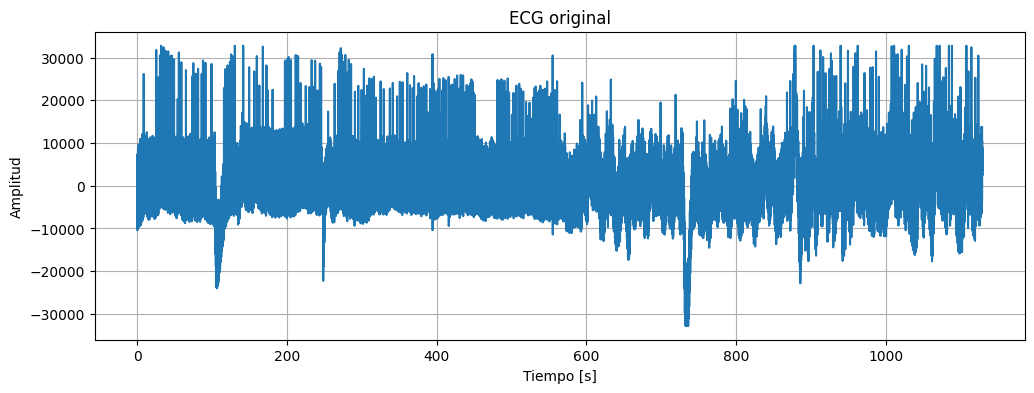

In [ ]:
#%% TS8
from scipy.signal import medfilt, correlate, find_peaks
from scipy.interpolate import CubicSpline
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio


#%% CARGA DEL ECG

mat_struct = sio.loadmat("./ECG_TP4.mat")
print(mat_struct.keys())

s = mat_struct["ecg_lead"].flatten()

qrs_detections = mat_struct["qrs_detections"].flatten().astype(int)
qrs_pattern1 = mat_struct["qrs_pattern1"].flatten()

fs = 1000
fn = fs / 2
cant_muestras = len(s)

t = np.arange(cant_muestras) / fs

# Gráfico del ECG original
plt.figure(figsize=(12, 4))
plt.plot(t, s)
plt.xlabel("Tiempo [s]")
plt.ylabel("Amplitud")
plt.title("ECG original")
plt.grid()
plt.show()

#Estimar b
#%% 1) Filtro de mediana -> utiliza ventanas móviles para eliminar las ondas 
# cardíacas y estimar el movimiento de la línea de base.

#filtro en cascada
L1 = round(0.2 * fs)
L2 = round(0.6 * fs)

# ventanas impares
if L1 % 2 == 0:
    L1 += 1

if L2 % 2 == 0:
    L2 += 1

# Primer filtro de mediana
m = medfilt(s, kernel_size=L1)

# Segundo filtro de mediana
b_estimada = medfilt(m, kernel_size=L2)

# Eliminación de la interferencia
x_estimada = s - b_estimada

#%% RESULTADOS FILTRO DE MEDIANA

plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(t, s)
plt.title("ECG original")
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(t, b_estimada)
plt.title("Línea de base estimada")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(t, x_estimada)
plt.title("ECG corregido - Filtro de mediana")
plt.xlabel("Tiempo [s]")
plt.grid()

plt.show()


#%% 2) spline cubico -> estima la línea de base mediante la interpolación de 
# puntos del ECG donde la actividad eléctrica cardíaca es
# aproximadamente nula.

# intervalor PQ es paroximadamente nulo
# Desplazamiento hacia el segmento PQ
n0 = round(0.06 * fs)

# Posición de los segmentos PQ
m2 = qrs_detections - n0

# Conservamos índices válidos
m2 = m2[(m2 >= 0) & (m2 < len(s))]
m2 = np.unique(m2)

# Amplitudes en los segmentos PQ
valores = s[m2]

# Construcción del spline
spline = CubicSpline(m2, valores)

# Estimación para todas las muestras
n = np.arange(len(s))
b_spline = spline(n)

# Eliminación de la interferencia
x_spline = s - b_spline

#%% RESULTADOS SPLINE CÚBICO

plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(t, s)
plt.plot(t[m2], valores, "r.", label="Puntos PQ")
plt.title("ECG original y puntos PQ")
plt.legend()
plt.grid()

plt.subplot(3, 1, 2)
plt.plot(t, b_spline)
plt.title("Línea de base estimada - Spline cúbico")
plt.grid()

plt.subplot(3, 1, 3)
plt.plot(t, x_spline)
plt.title("ECG corregido - Spline cúbico")
plt.xlabel("Tiempo [s]")
plt.grid()

plt.show()

#%% COMPARACIÓN DE MÉTODOS

plt.figure(figsize=(12, 4))
plt.plot(t, b_estimada, label="Filtro de mediana")
plt.plot(t, b_spline, label="Spline cúbico")
plt.title("Comparación de líneas de base estimadas")
plt.xlabel("Tiempo [s]")
plt.legend()
plt.grid()
plt.show()

#%% Filtro adaptado -> detecta los latidos mediante la correlación entre la señal 
# ECG y un patrón conocido del complejo QRS.

patron = qrs_pattern1
patron = patron - np.mean(patron) # Para que el filtro adaptado se concentre en
# reconocer la forma del complejo QRS y no se vea tan afectado por los 
#desplazamientos verticales de la señal


# Aplicación del filtro adaptado
y = correlate(x_estimada, patron, mode="same")

# Umbral
umbral = 0.3 * np.max(y) #30% para asegurarse de no perder datos, 
# con este umbral se obtiene una cantidad de latidos similar a los de referencia

# Distancia mínima entre latidos
distancia = round(0.3 * fs)  # Se utiliza para evitar que el algoritmo detecte varias veces un mismo
# latido o confunda otros picos cercanos con latidos independientes.

# Detección de máximos
detecciones, propiedades = find_peaks(y, height=umbral, distance=distancia)

#%% RESULTADOS FILTRO ADAPTADO

plt.figure(figsize=(12, 4))
plt.plot(t, y, label="Correlación")
plt.axhline(umbral, color="r", linestyle="--", label="Umbral")
plt.plot(t[detecciones], y[detecciones], "go", label="Latidos detectados")
plt.xlabel("Tiempo [s]")
plt.title("Detección de latidos")
plt.xlim(0, 100)
plt.legend()
plt.grid()
plt.show()

print("Latidos de referencia:", len(qrs_detections))
print("Latidos detectados:", len(detecciones))